- **Disclaimer** - No `trading tips` given!

### RNN & LSTM Hands-on using `Tesla Stock Prices Data`

In [2]:
# ----- Core data handling & OS -----
import numpy as np                          # numerical operations, arrays
import pandas as pd                         # dataframes, CSV I/O
import os                                    # file system utilities (e.g. checking current directory)

# ----- Visualization -----
import matplotlib.pyplot as plt             # primary plotting library
import seaborn as sns                       # statistical plots (heatmaps, distribution plots) built on matplotlib

# ----- Deep Learning (TensorFlow / Keras) -----
import tensorflow as tf                     # TensorFlow backend, needed to set the global random seed
from tensorflow.keras.models import Sequential      # linear stack-of-layers model API
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout  # layer types we will use
from tensorflow.keras.callbacks import EarlyStopping                  # stops training once the model stops improving

# ----- Preprocessing & Metrics -----
from sklearn.preprocessing import MinMaxScaler                         # scales data into a fixed range (0,1)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # quantitative evaluation metrics

# ----- Reproducibility -----
SEED = 42                                   # a fixed "arbitrary" seed value used everywhere below
np.random.seed(SEED)                        # fixes NumPy's random number generator (affects e.g. shuffling)
tf.random.set_seed(SEED)                    # fixes TensorFlow's random number generator (affects weight init, dropout)

# ----- Cosmetic plotting defaults -----
sns.set_style("whitegrid")                  # clean grid background for all seaborn/matplotlib plots
plt.rcParams["figure.dpi"] = 100            # sharper default plot resolution


## 1. Load the `Tesla` Data

In [3]:
from pathlib import Path
project_data = Path("data/Tesla.csv.csv")
data = pd.read_csv(project_data)
data.sample(5)

,Date,Open,High,Low,Close,Volume,Adj Close
989,6/4/2014,204.350006,206.259995,200.399994,203.990005,3427400,203.990005
1637,12/28/2016,221.529999,223.800003,217.199997,219.740005,3782500,219.740005
1217,4/30/2015,230.389999,232.889999,225.169998,226.050003,3911900,226.050003
1175,3/2/2015,202.699997,203.339996,195.830002,197.330002,7922100,197.330002
1373,12/10/2015,224.710007,228.490005,223.639999,227.070007,2067000,227.070007




1. **Open:** The opening price of the stock on a particular trading day. This is the price at which the first trade is executed when the market opens.
2.  **High:** The highest price at which the stock traded during the `trading day`. It indicates the maximum value that traders were willing to pay for the stock on that day.
3. **Low:** The lowest price at which the stock traded during the trading day. This represents the minimum value for the stock within the trading day.
4. **Close:** The closing price of the stock for the day. It is the last price at which the stock was traded before the market closed. This is one of the most commonly reported and used prices because it reflects the final consensus value of the stock for the day.
5. **Volume:** The total number of shares or contracts traded for the stock during the trading day. It reflects the level of activity or liquidity for the stock. Higher volume indicates more trading activity and, typically, higher investor interest.
6. **Adj Close (Adjusted Close):** This is the closing price adjusted for corporate actions like `stock splits`, `dividends`, and `new stock offerings`. Adjusted close provides a more accurate reflection of a stock’s value and price movements over time because it accounts for events that could affect the stock price directly.

## 2. Exploratory Data Analysis (EDA)

Before building any model, we need to understand the shape, quality, and behaviour of the data. For time-series/financial data specifically, we care about:
- **Structure**: rows, columns, datatypes
- **Data quality**: missing values, duplicate dates
- **Distribution**: how prices are spread out
- **Trend & seasonality**: is the stock generally rising/falling, and over what time horizons
- **Volatility**: how much the price swings day-to-day
- **Relationships between columns**: e.g. Open vs Close vs Volume correlation

This EDA directly informs modelling choices later (e.g. scaling is required because prices span a wide range; the "sliding window" length is chosen based on how much recent history seems to matter).


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1692 entries, 0 to 1691
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1692 non-null   object 
 1   Open       1692 non-null   float64
 2   High       1692 non-null   float64
 3   Low        1692 non-null   float64
 4   Close      1692 non-null   float64
 5   Volume     1692 non-null   int64  
 6   Adj Close  1692 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 92.7+ KB


- `Date column` is not in the `standard date format`

In [5]:
data.describe() # summary statistics (count, mean, median, std, quartiles etc.) for every numeric column

,Open,High,Low,Close,Volume,Adj Close
count,1692.000000,1692.000000,1692.000000,1692.000000,1.692000e+03,1692.000000
mean,132.441572,134.769698,129.996223,132.428658,4.270741e+06,132.428658
std,94.309923,95.694914,92.855227,94.313187,4.295971e+06,94.313187
min,16.139999,16.629999,14.980000,15.800000,1.185000e+05,15.800000
25%,30.000000,30.650000,29.215000,29.884999,1.194350e+06,29.884999
50%,156.334999,162.370002,153.150002,158.160004,3.180700e+06,158.160004
75%,220.557495,224.099999,217.119999,220.022503,5.662100e+06,220.022503
max,287.670013,291.420013,280.399994,286.040009,3.716390e+07,286.040009


### Let us check if there is any `missing data`

In [6]:
data.isna().sum() #count missing data values per column

Date         0
Open         0
High         0
Low          0
Close        0
Volume       0
Adj Close    0
dtype: int64

- No missing data and we are good!

#### Convert `Date` column to a proper `datetime` type

In [7]:
data['Date'] = pd.to_datetime(data['Date'])

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1692 entries, 0 to 1691
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1692 non-null   datetime64[ns]
 1   Open       1692 non-null   float64       
 2   High       1692 non-null   float64       
 3   Low        1692 non-null   float64       
 4   Close      1692 non-null   float64       
 5   Volume     1692 non-null   int64         
 6   Adj Close  1692 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 92.7 KB


In [9]:
data.sample(5)

,Date,Open,High,Low,Close,Volume,Adj Close
314,2011-09-26,26.520000,26.520000,24.900000,25.520000,934800,25.520000
809,2013-09-16,168.000000,170.850006,165.850006,166.580002,7574900,166.580002
723,2013-05-14,94.220001,97.120003,81.150002,83.239998,37163900,83.239998
305,2011-09-13,23.010000,24.100000,22.750000,24.080000,726500,24.080000
68,2010-10-05,21.150000,21.280001,21.010000,21.120001,332000,21.120001


### Let us plot the `Open Price` distribution
- using `Pandas DataFrame`

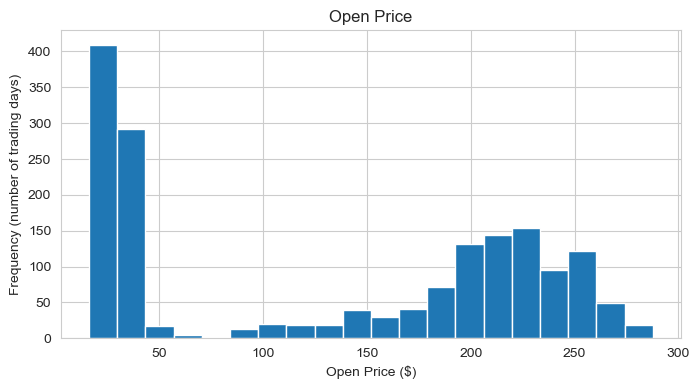

In [10]:
plt.subplots(figsize=(8, 4))                                  # create a figure with a specific size (width=8in, height=4in)
data['Open'].plot(kind='hist', bins=20, title='Open Price')  # histogram of Open price with 20 bins
plt.xlabel("Open Price ($)")                                  # label the x-axis
plt.ylabel("Frequency (number of trading days)")              # label the y-axis
plt.show()                                                     # render the plot

In [11]:
print("Number of trading days in Tesla data:", data['Date'].nunique())

Number of trading days in Tesla data: 1692


In [12]:
1692/300

5.64

In [13]:
data['Date'].min(), data['Date'].max()

(Timestamp('2010-06-29 00:00:00'), Timestamp('2017-03-17 00:00:00'))

**📌 Takeaway:** ~4.6 years of daily trading history. Markets are open roughly 252 days/year (not 365, since weekends and public holidays are excluded) — so this dataset actually spans closer to **6.5–7 calendar years** of trading activity. Keep this in mind: a `time_step` of 50 (used later) represents roughly **10 trading weeks**, i.e. about 2.5 months of recent price history the model "looks back" on for every prediction.

### Full time-series view: `Open`, `High`, `low`, `Close` over time

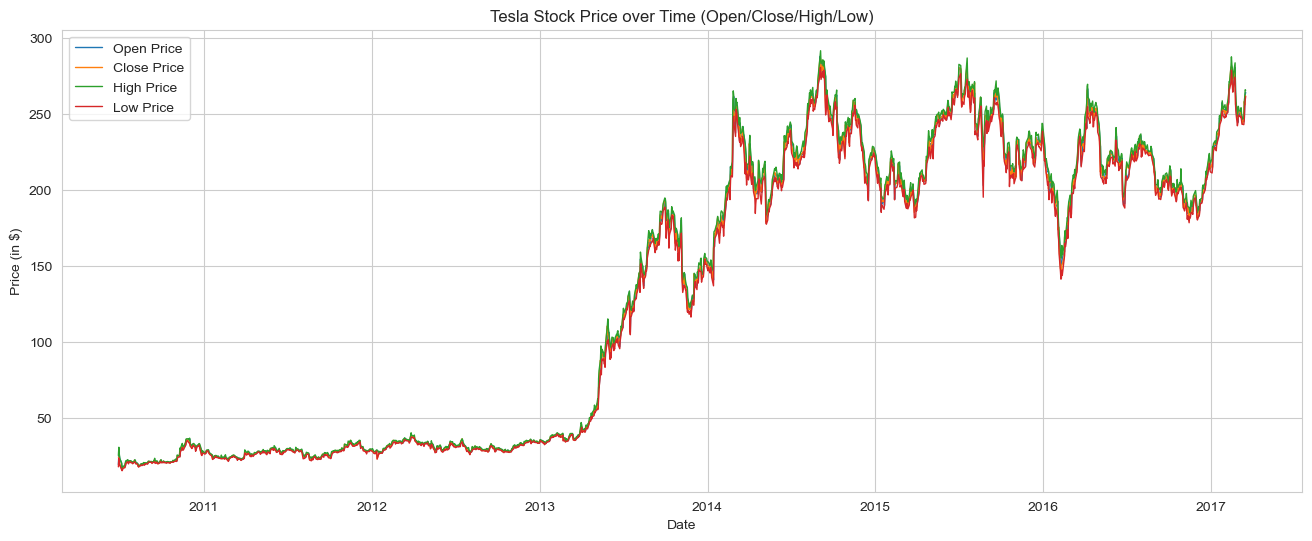

In [14]:
plt.figure(figsize = (16,6))
plt.plot(data['Date'], data['Open'], label='Open Price', linewidth = 1) #plotting open price over time
plt.plot(data['Date'], data['Close'], label='Close Price', linewidth = 1) #plotting close price over time
plt.plot(data['Date'], data['High'], label='High Price', linewidth = 1) #plotting high price over time
plt.plot(data['Date'], data['Low'], label='Low Price', linewidth = 1) #plotting low price over time

plt.title("Tesla Stock Price over Time (Open/Close/High/Low)")
plt.xlabel("Date")
plt.ylabel("Price (in $)")
plt.legend()
plt.show()

- Observation: Since there is so much data in a small canvas which is static you are not able to understand much!!!!!

In [15]:
# pip install plotly

In [16]:
import plotly.graph_objects as go

fig = go.Figure()
for col in ["Open", "Close", "High", "Low"]:
    fig.add_trace(go.Scatter(x=data["Date"], y=data[col], mode="lines",
                             name=f"{col} Price", line=dict(width=1)))

fig.update_layout(
    title="Tesla Stock Price over Time (Open/Close/High/Low)",
    xaxis_title="Date",
    yaxis_title="Price (in $)",
    hovermode="x unified",          # one tooltip showing all four prices
    height=550,
    xaxis=dict(
        rangeslider=dict(visible=True),   # drag the handles to zoom on the date range
        rangeselector=dict(buttons=[
            dict(count=1, label="1M", step="month", stepmode="backward"),
            dict(count=6, label="6M", step="month", stepmode="backward"),
            dict(count=1, label="1Y", step="year",  stepmode="backward"),
            dict(step="all", label="All"),
        ]),
    ),
)
fig.show()

## 3. Objective & Train / Validation Split

**Objective:** Predict the `Open` price of Tesla stock for a given trading day, using the previous `time_step` days of `Open` prices as context.

### ⚠️ Why we do NOT use `train_test_split` with shuffling here

For most ML problems, `sklearn.model_selection.train_test_split(..., shuffle=True)` is standard. For **time series**, shuffling is a serious mistake:
- It would let the model "see" future prices while training on past ones (`temporal leakage`)
- Financial time series has autocorrelation — order matters, and randomizing destroys the very sequence structure the RNN/LSTM is meant to learn

**Correct approach:** Split **chronologically**. Everything before a cut-off date is `train`, everything after is `validation`. This mimics real deployment: "train on history, predict the future."


In [17]:
split_ratio = 0.70 #reserve 70% 0f the time-series data (sequentially ordered) for training and the remaining 30% for validation
length_data = len(data) #total number of rows in Tesla data
length_train = round(length_data * split_ratio) #number of rows that belong to the training period
length_validation = length_data - length_train #number of rows that belong to the validation period

In [18]:
print("Data Length:", length_data)                # total trading days available
print("Train data length:", length_train)         # size of the training period
print("Validation data length:", length_validation)  # size of the validation (held-out, "future") period

Data Length: 1692
Train data length: 1184
Validation data length: 508


## 4. Preparing the Training Array

Keras layers expect NumPy arrays, not pandas Series, and `MinMaxScaler` specifically expects a **2D** array of shape `(n_samples, n_features)` — even when we only have 1 feature (`Open`). So we first pull out the raw values, then reshape from 1D to 2D.


In [19]:
train_data = data[:length_train][['Date', 'Open']] #training set
validation_data = data[length_train:][['Date', 'Open']] #validation set

In [20]:
print("Train period      :", train_data['Date'].min().date(), "->", train_data['Date'].max().date())        # training date range
print("Validation period :", validation_data['Date'].min().date(), "->", validation_data['Date'].max().date())  # validation date range

Train period      : 2010-06-29 -> 2015-03-12
Validation period : 2015-03-13 -> 2017-03-17


### Normalization / Feature Scaling

- dataset values will be scaled into the range **`0 to 1`** after scaling

**Why scaling matters for RNN/LSTM specifically:**
1. Both `SimpleRNN` and `LSTM` use the **`tanh`** activation by default, which saturates (flattens, gradient ≈ 0) for large positive/negative inputs. Feeding in raw prices like \$1200 would push activations deep into the saturated region, stalling learning.
2. Large, unscaled inputs make gradients unstable during **Backpropagation Through Time (BPTT)** — contributing to the **vanishing/exploding gradient problem**, which recurrent networks are already prone to over long sequences.
3. Gradient-based optimizers (like `Adam`) converge faster and more reliably when all input features share a similar, bounded scale.

We fit the scaler **only on the training data** and reuse the exact same fitted scaler for the validation data later (see Section 6) — fitting on validation data too would leak information about the future price range into training, which is a subtle but common bug in stock-prediction tutorials.


In [21]:
dataset_train = train_data['Open'].values #extract just the open price column as the 1D array
dataset_train[:10]

array([19.      , 25.790001, 25.      , 23.      , 20.      , 16.4     ,
       16.139999, 17.58    , 17.950001, 17.389999])

In [22]:
dataset_train.ndim

1

- ML/DL models need **2-D** arrays

In [23]:
dataset_train = np.reshape(dataset_train, (-1, 1)) #reshape 1D array --> 2D array
dataset_train.shape

(1184, 1)

In [24]:
dataset_train.ndim

2

In [25]:
scaler = MinMaxScaler(feature_range=(0, 1))                 # scaler that will squeeze values into the [0, 1] range
dataset_train_scaled = scaler.fit_transform(dataset_train)  # fit the scaler using ONLY training data statistics (min/max), then transform

In [26]:
dataset_train.min(), dataset_train.max() #original before scaling

(np.float64(16.139999), np.float64(287.670013))

In [27]:
dataset_train_scaled.min(), dataset_train_scaled.max() # after scaling

(np.float64(0.0), np.float64(1.0))

### Let us visualize the `line chart` for `Tesla` Stock Open Price - Before vs After Scaling

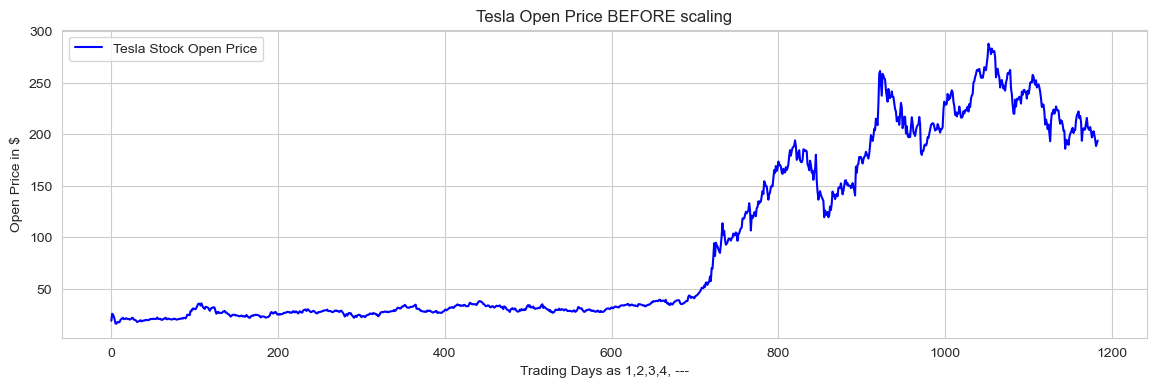

In [28]:
plt.subplots(figsize=(14, 4))                                        # figure sized for a single wide line chart
plt.plot(dataset_train, color='blue', label='Tesla Stock Open Price')  # raw (unscaled) training price series
plt.title('Tesla Open Price BEFORE scaling')                          # chart title
plt.xlabel('Trading Days as 1,2,3,4, ---')                             # x-axis: sequential trading-day index (not calendar dates)
plt.ylabel('Open Price in $')                                          # y-axis label
plt.legend()                                                           # show legend
plt.show()                                                             # render the plot


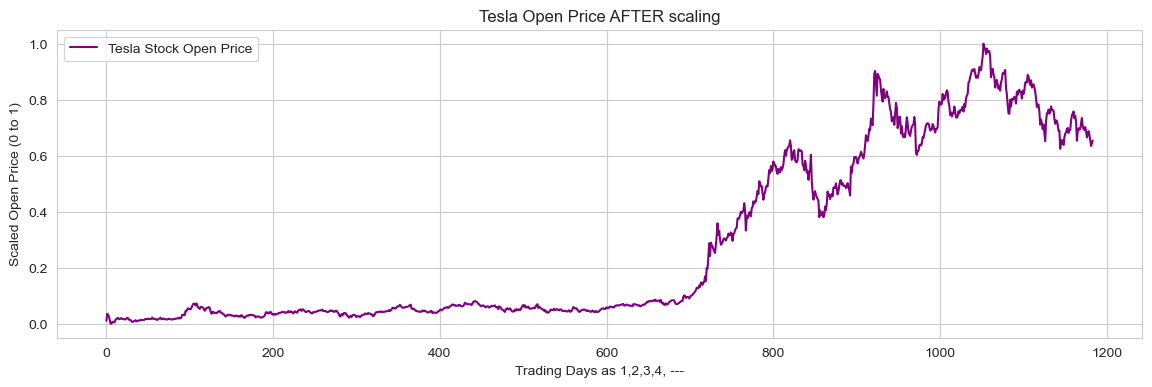

In [29]:
plt.subplots(figsize=(14, 4))                                              # figure sized for a single wide line chart
plt.plot(dataset_train_scaled, color='purple', label='Tesla Stock Open Price')   # scaled training price series
plt.title('Tesla Open Price AFTER scaling')                                # chart title
plt.xlabel('Trading Days as 1,2,3,4, ---')                                  # x-axis: sequential trading-day index
plt.ylabel('Scaled Open Price (0 to 1)')                                    # y-axis label
plt.legend()                                                                # show legend
plt.show()                                                                  # render the plot


## 5. Sequence (Sliding Window) Creation

This is the single most important data-prep concept for RNN/LSTM and is worth slowing down on.

A `SimpleRNN`/`LSTM` layer does not consume a flat list of prices — it consumes **sequences**: for every prediction, it needs a fixed-length *window* of past values as input, and the next value as the target (label).

We choose `time_step = 50`, meaning: *"use the last 50 trading days of Open price to predict day 51."*

**Worked example** (with scaled values `p1, p2, p3, ... pN`):

| Sample | X (input window)          | y (target) |
|--------|----------------------------|------------|
| 1      | `p1, p2, ..., p50`         | `p51`      |
| 2      | `p2, p3, ..., p51`         | `p52`      |
| 3      | `p3, p4, ..., p52`         | `p53`      |
| ...    | ...                         | ...        |

Each window slides forward by **one day** at a time (a "rolling" or "sliding" window), giving us `length_train - time_step` overlapping training samples out of a series that originally had only `length_train` points. This overlapping-window trick is how we generate enough training examples from a single time series.


In [30]:
X_train = [] # will hold the input windows (each a list of 50 scaled prices)
y_train = [] # will hold the corresponding targets (the scaled price on day 51, 52, 53...so on and so forth)

time_step = 50 # length of look-back window: how many past days the model sees per prediction

for i in range(time_step, length_train): #starting at index 50 (first index with a full 50-day history available)
    X_train.append(dataset_train_scaled[i - time_step: i, 0]) #the 50 days before day i -> Input Window
    y_train.append(dataset_train_scaled[i, 0]) # the price on day i --> target / label

In [31]:
X_train

[array([0.01053291, 0.03553936, 0.03262991, 0.02526425, 0.01421574,
        0.00095754, 0.        , 0.00530328, 0.00666594, 0.00460354,
        0.00662911, 0.01399478, 0.01679373, 0.01926123, 0.02102899,
        0.01664641, 0.01605716, 0.01859832, 0.01973999, 0.01756712,
        0.0162413 , 0.01705153, 0.01495231, 0.01605716, 0.01789858,
        0.02139727, 0.01988731, 0.01458403, 0.01384746, 0.01292675,
        0.00939123, 0.0061135 , 0.00751299, 0.00850735, 0.01038559,
        0.01270578, 0.00883881, 0.00924392, 0.01086436, 0.01145362,
        0.01112216, 0.01381063, 0.01329503, 0.0131109 , 0.01296358,
        0.01281627, 0.0155784 , 0.01741981, 0.01646228, 0.01664641]),
 array([0.03553936, 0.03262991, 0.02526425, 0.01421574, 0.00095754,
        0.        , 0.00530328, 0.00666594, 0.00460354, 0.00662911,
        0.01399478, 0.01679373, 0.01926123, 0.02102899, 0.01664641,
        0.01605716, 0.01859832, 0.01973999, 0.01756712, 0.0162413 ,
        0.01705153, 0.01495231, 0.01605716, 0.

In [32]:
### Convert the list into arrays
X_train, y_train = np.array(X_train), np.array(y_train)

In [33]:
print("Shape of X_train before reshape:", X_train.shape)   # currently 2D: (num_samples, time_step)
print("Shape of y_train before reshape:", y_train.shape)   # currently 1D: (num_samples,)

Shape of X_train before reshape: (1134, 50)
Shape of y_train before reshape: (1134,)


### Why we need a 3rd dimension

Keras recurrent layers (`SimpleRNN`, `LSTM`) always expect input of shape **`(batch_size, timesteps, n_features)`** — a strict 3D tensor, even when `n_features = 1` (as it is here, since we're only using `Open` price). `X_train` is currently 2D `(samples, timesteps)`, so we add a trailing dimension of size 1 to represent "1 feature per timestep."


In [34]:
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))  # (samples, timesteps) -> (samples, timesteps, 1_feature)
y_train = np.reshape(y_train, (y_train.shape[0], 1))                       # (samples,) -> (samples, 1) for consistency with Keras' expected label shape

print("Shape of X_train after reshape :", X_train.shape)   # now 3D: (num_samples, 50, 1) -> ready for RNN/LSTM input
print("Shape of y_train after reshape :", y_train.shape)   # now 2D: (num_samples, 1)


Shape of X_train after reshape : (1134, 50, 1)
Shape of y_train after reshape : (1134, 1)


In [35]:
# Concatenate the full Open-price history (train + validation) in chronological order.
# We need this because the first validation window has to "reach back" into the tail end of the training data.
dataset_total = pd.concat((train_data['Open'], validation_data['Open']), axis=0)

# Slice out exactly: (last `time_step` days of train) + (all of validation).
# len(dataset_total) - len(validation_data) - time_step  =  the index where this window starts.
inputs = dataset_total[len(dataset_total) - len(validation_data) - time_step:].values
inputs = inputs.reshape(-1, 1)          # reshape 1D -> 2D, same requirement as before ( (-1,1) infers the row count)

inputs = scaler.transform(inputs)       # IMPORTANT: reuse the scaler fitted on TRAIN data only -> .transform(), never .fit_transform() here


In [36]:
X_test = []   # will hold the input windows for every validation-period trading day
y_test = []   # will hold the corresponding ACTUAL (unscaled) Open prices for those days

for i in range(time_step, time_step + length_validation):    # walk forward one window per validation day
    X_test.append(inputs[i - time_step: i, 0])                # the 50 scaled days immediately BEFORE day i -> input window

X_test = np.array(X_test)                                       # convert list of windows -> NumPy array, shape (n_val, 50)
y_test = validation_data['Open'].values.reshape(-1, 1)          # ground-truth Open prices, kept in ORIGINAL dollar scale (no transform needed)

In [37]:
print("Shape of X_test before reshape :", X_test.shape)   # currently 2D: (num_validation_samples, time_step)
print("Shape of y_test                     :", y_test.shape)   # (num_validation_samples, 1), already in $ scale

Shape of X_test before reshape : (508, 50)
Shape of y_test                     : (508, 1)


In [38]:
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))   # 2D -> 3D: (samples, timesteps, 1_feature), same as X_train

print("Shape of X_test after reshape :", X_test.shape)   # now ready to feed into either the RNN or the LSTM model


Shape of X_test after reshape : (508, 50, 1)


## 7. Building the Simple RNN Model

📚 Reference: [Keras `SimpleRNN` documentation](https://keras.io/api/layers/recurrent_layers/simple_rnn/)

### Architecture recap
We stack **4 `SimpleRNN` layers** (50 units each) with `Dropout(0.2)` between the middle layers, followed by a single `Dense(1)` output neuron.

| Concept | Why it's used here |
|---|---|
| `units=50` | Size of the hidden state vector — how much "memory" each recurrent cell carries forward at every timestep |
| `activation='tanh'` | Keras' default for `SimpleRNN`; bounded output (-1, 1) keeps the recurrent hidden state numerically stable across timesteps |
| `return_sequences=True` | Required whenever a recurrent layer feeds into **another** recurrent layer — it must output its hidden state at *every* timestep (not just the last one), so the next RNN layer has a full sequence to consume |
| `return_sequences=False` (default, used on the **last** RNN layer) | We only need the *final* hidden state — the summary of the entire 50-day window — to hand off to the `Dense` output layer |
| `Dropout(0.2)` | Randomly zeroes 20% of the units' outputs during training, forcing the network to not over-rely on any single unit — a standard regularizer against overfitting |
| `Dense(units=1)` | The output layer: a single neuron producing one continuous number — the predicted (scaled) next-day Open price |

> ⚠️ **Known weakness of `SimpleRNN`:** across long sequences, gradients during Backpropagation Through Time (BPTT) tend to shrink multiplicatively at every timestep — the **vanishing gradient problem**. This makes plain RNNs struggle to learn dependencies from far back in the window. We'll see how LSTM's gating mechanism directly addresses this — see Section 9 for a hands-on demonstration of vanishing/exploding gradients, and Section 10 for the LSTM fix.


In [39]:
regressor = Sequential() # initialize an empty linear stack of layers' model

# ---- Layer 1: first RNN layer, must declare input_shape (timesteps, features) ----
regressor.add(
    SimpleRNN(units=50, activation='tanh', return_sequences=True,
              input_shape=(X_train.shape[1], 1))   # (50 timesteps, 1 feature) - matches X_train's shape
)

# ---- Layer 2: second RNN layer + dropout regularization ----
regressor.add(SimpleRNN(units=50, activation='tanh', return_sequences=True))  # still feeding into another RNN layer -> keep full sequence
regressor.add(Dropout(0.2))   # drop 20% of units' activations at random each training step, to reduce overfitting

# ---- Layer 3: third RNN layer + dropout regularization ----
regressor.add(SimpleRNN(units=50, activation='tanh', return_sequences=True))  # again feeding another RNN layer
regressor.add(Dropout(0.2))   # regularization

# ---- Layer 4: fourth (final) RNN layer + dropout regularization ----
regressor.add(SimpleRNN(units=50))    # return_sequences defaults to False here -> outputs only the FINAL hidden state (a single vector per sample)
regressor.add(Dropout(0.2))           # regularization on the final RNN output before the Dense layer

# ---- Output layer ----
regressor.add(Dense(units=1))   # a single fully-connected neuron -> the predicted (scaled) next-day Open price

regressor.summary()   # print a table of every layer, its output shape, and parameter count -> a quick sanity check of the architecture


<local Python environment>\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50, 50)         │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 50, 50)         │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 50, 50)         │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,801 (69.54 KB)

 Trainable params: 17,801 (69.54 KB)

 Non-trainable params: 0 (0.00 B)

### Compiling & Training

In [40]:
regressor.compile(
    optimizer= 'adam',
    loss = 'mean_squared_error',
    metrics = ['mae']
)

early_stop = EarlyStopping(
    monitor = 'loss', #watching the training loss
    patience = 5, #allow 5 epochs of no improvement before stopping
    restore_best_weights= True #roll back to the weights from the best epoch once stopped (lowest-loss)
)

history = regressor.fit(
    X_train, y_train,
    epochs = 50,
    batch_size=32,
    callbacks=[early_stop], #attach the early-stopping safeguard defined above
    verbose = 1 #prints one line of progress per epoch
)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.5542 - mae: 0.5768
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.2306 - mae: 0.3828
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.1755 - mae: 0.3255
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.1127 - mae: 0.2612
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0773 - mae: 0.2135
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0548 - mae: 0.1731
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0391 - mae: 0.1488
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0329 - mae: 0.1290
Epoch 9/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0296 - mae: 0.1232
Epoch 10/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0228 - mae: 0.1049
Epoch 11/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0210 - mae: 0.0987
Epoch 12/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0163 - mae: 0.0895
Epoch 13/50
36/36 ━━━━━━━━━━━━━━━━━━━

## 8. Evaluating the RNN Model

### 8.1 On the Training Set (sanity check — "did it learn the training data at all?")


In [41]:
y_pred = regressor.predict(X_train) # OPTIONAL but can run the  trained model on the SAME window it was trained on

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


In [42]:
y_train_actual = scaler.inverse_transform(y_train) #convert scaled TRAINING ACTUALs back to real dollar values
y_pred_actual = scaler.inverse_transform(y_pred) #convert scaled TRAINING PREDICTIONS back to real dollar values

### Let us plot the actual vs predicted `training`  → TRAINING FIT

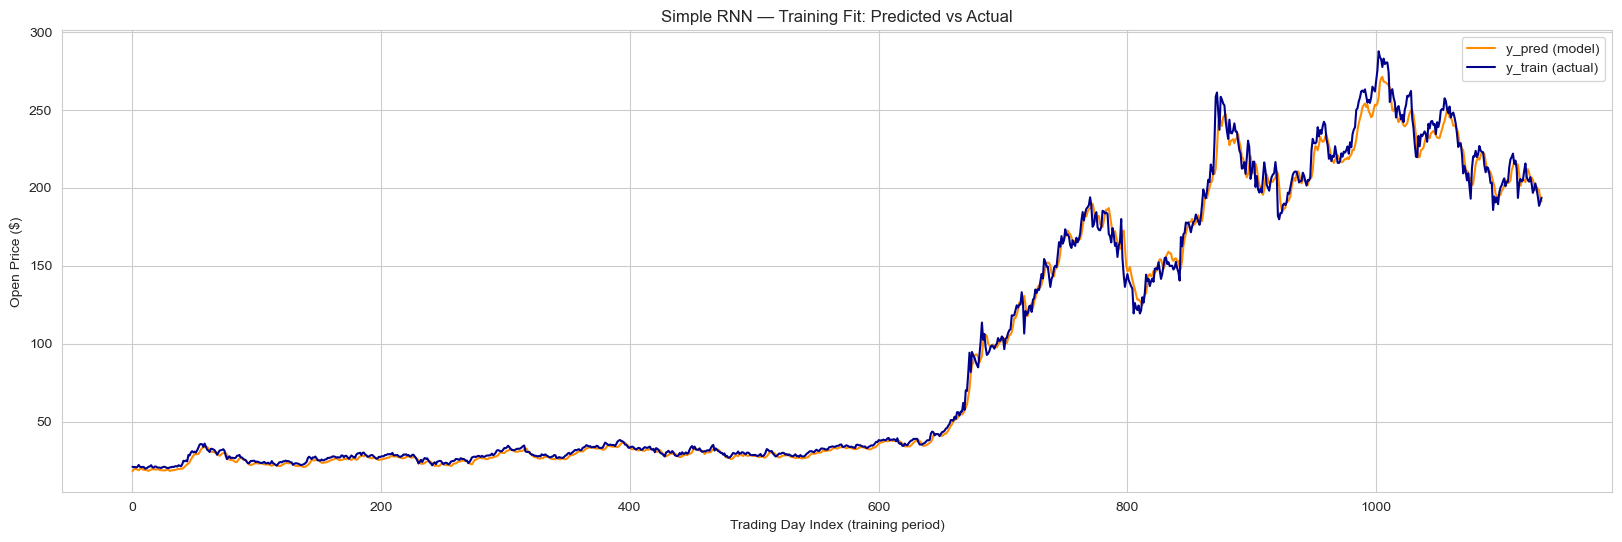

In [43]:
plt.figure(figsize=(20, 6))                                                     # wide figure to see the full multi-year training fit clearly
plt.plot(y_pred_actual, color='darkorange', label="y_pred (model)")           # model's predicted Open price on training data
plt.plot(y_train_actual, color="darkblue",  label="y_train (actual)")         # ground-truth Open price on training data
plt.xlabel("Trading Day Index (training period)")                              # x-axis label
plt.ylabel("Open Price ($)")                                                    # y-axis label
plt.title("Simple RNN — Training Fit: Predicted vs Actual")                    # chart title
plt.legend()                                                                    # show legend
plt.show()                                                                      # render the plot

**📌 Takeaway:** A close overlap here confirms the model has successfully *fit* the training data — but this alone does **not** prove it will generalize. A model that memorizes training noise can still look perfect on this chart while performing poorly on unseen data — which is exactly why Section 8.2 (validation) is the metric that actually matters.

### 8.2 On the Validation Set (the real test — data the model has *never* seen)

In [44]:
y_pred_of_test = regressor.predict(X_test) #predict on the held-out validation windows --> which is never seen during training

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [45]:
y_pred_of_test = scaler.inverse_transform(y_pred_of_test) #convert scaled predictions back to real dollar values

### Let us visualize the `Predicted` vs `Actual` for the validation set

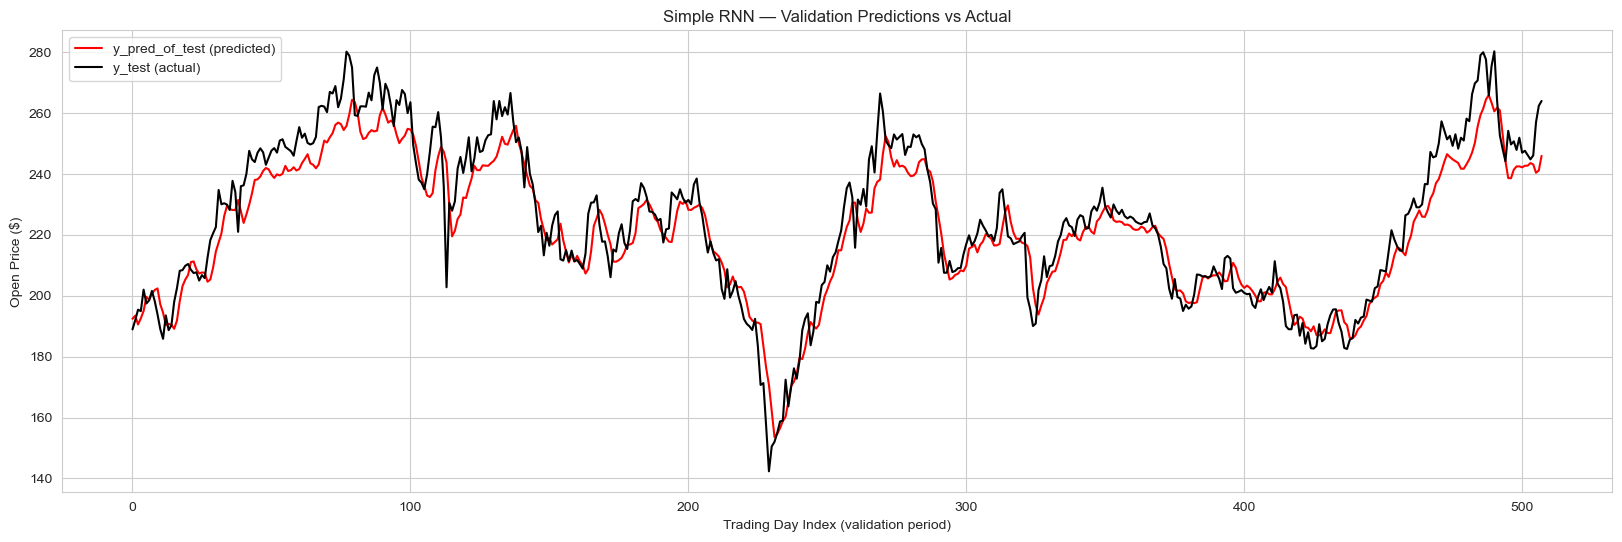

In [46]:
plt.figure(figsize=(20, 6))                                                        # wide figure to see the full validation period clearly
plt.plot(y_pred_of_test, label="y_pred_of_test (predicted)", c="red")            # model's predicted Open price on validation data
plt.plot(y_test,          label="y_test (actual)",             c="black")         # ground-truth Open price on validation data
plt.xlabel("Trading Day Index (validation period)")                               # x-axis label
plt.ylabel("Open Price ($)")                                                       # y-axis label
plt.title("Simple RNN — Validation Predictions vs Actual")                        # chart title
plt.legend()                                                                       # show legend
plt.show()                                                                         # render the plot


### Full Picture: Train → Validation → Prediction, in one chart

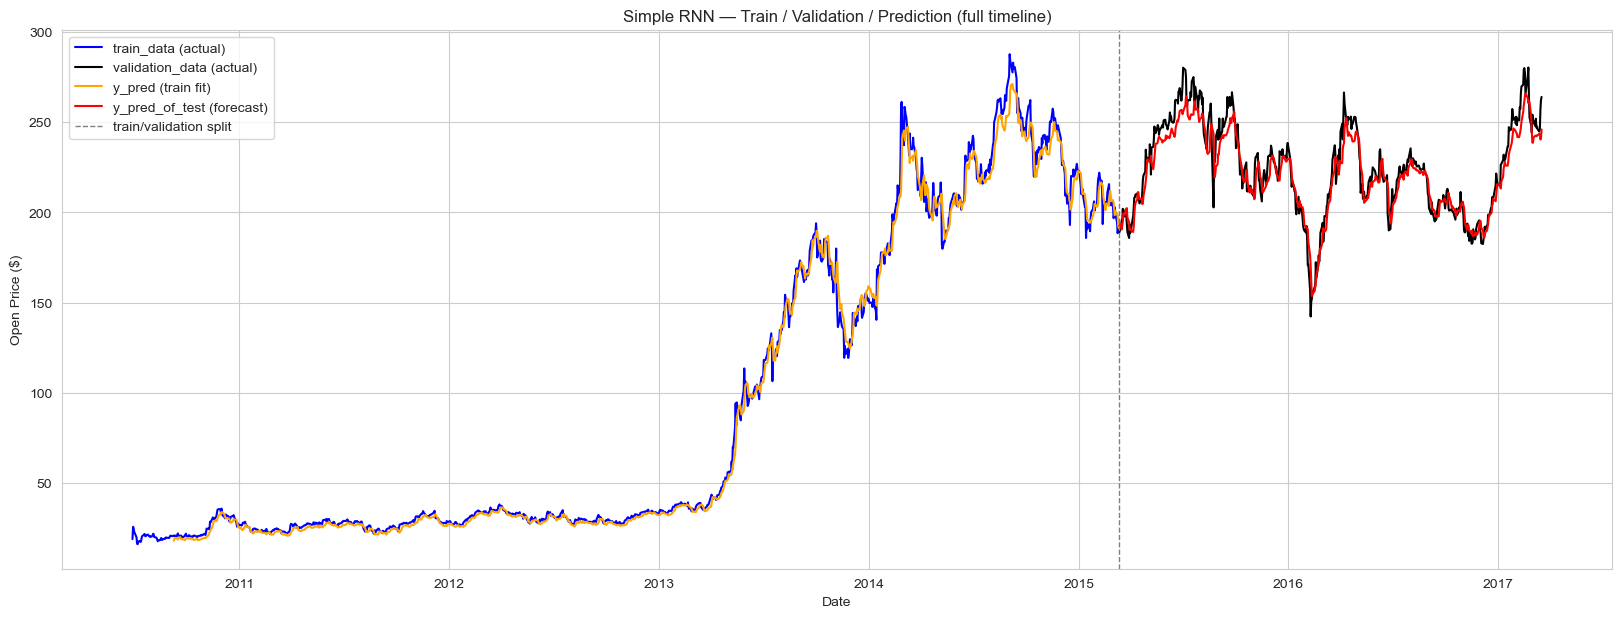

In [47]:
plt.subplots(figsize=(20, 7))                                                                          # wide figure spanning the full timeline
plt.plot(train_data['Date'], train_data['Open'], label="train_data (actual)", color="blue")                # actual training-period Open prices
plt.plot(validation_data['Date'], validation_data['Open'], label="validation_data (actual)", color="black")  # actual validation-period Open prices
plt.plot(train_data['Date'].iloc[time_step:], y_pred_actual, label="y_pred (train fit)", color="orange")    # model's fit on training windows
plt.plot(validation_data['Date'], y_pred_of_test, label="y_pred_of_test (forecast)", color="red")           # model's forecast on validation windows
plt.axvline(train_data['Date'].iloc[-1], color='gray', linestyle='--', linewidth=1, label='train/validation split')  # mark the split point
plt.xlabel("Date")                                                                                            # x-axis label
plt.ylabel("Open Price ($)")                                                                                   # y-axis label
plt.title("Simple RNN — Train / Validation / Prediction (full timeline)")                                     # chart title
plt.legend()                                                                                                   # show legend
plt.show()                                                                                                     # render the plot


## **Original tesla stocks insights**

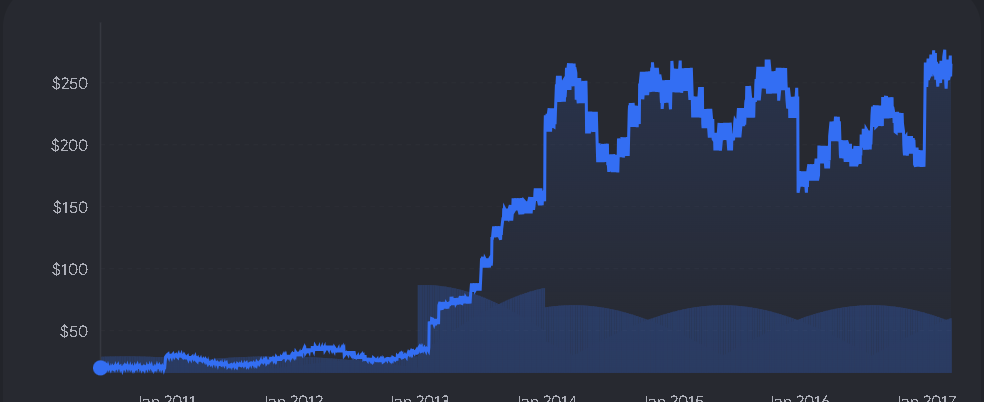

**📌 Takeaway (RNN section summary):**
- The RNN generally tracks the *direction* of the validation-period price well, since consecutive stock prices are highly autocorrelated (tomorrow tends to be close to today).
- Look closely at sharp reversals/spikes in the validation chart — a plain `SimpleRNN` often **lags** behind sudden changes, predicting something close to "yesterday's price" rather than truly anticipating the move. This is a visible symptom of the vanishing-gradient limitation discussed earlier: the recurrent memory struggles to weigh distant-past information as strongly as it should.
- The MAE/RMSE/R² numbers above are our RNN baseline — we'll now build an LSTM on the *exact same* data and see whether its gating mechanism improves on this baseline.


## 9. Building the LSTM Model

### Why LSTM over a plain RNN?

`LSTM` (Long Short-Term Memory) was designed specifically to fix `SimpleRNN`'s vanishing-gradient weakness. Instead of a single hidden state that gets overwritten at every timestep, an LSTM cell maintains a separate **cell state** (a kind of "conveyor belt" of memory) regulated by three learned **gates**:

| Gate | Question it answers | Effect |
|---|---|---|
| **Forget gate** | "How much of the old cell state should I discard?" | Lets the network drop irrelevant old information |
| **Input gate** | "How much of the new candidate information should I add?" | Lets the network selectively write new information into memory |
| **Output gate** | "How much of the cell state should I expose as this timestep's output?" | Controls what gets passed forward to the next layer/timestep |

Because the cell state is updated mostly through **additive** interactions (rather than being repeatedly squashed through a `tanh`/matrix-multiply chain like in `SimpleRNN`), gradients can flow backward through many timesteps with far less decay — directly addressing the vanishing-gradient problem and letting LSTM capture longer-range dependencies in the 50-day window.

### Architecture recap
We use **2 stacked `LSTM` layers** (64 units each) followed by a `Dense(32)` hidden layer and a `Dense(1)` output layer — deliberately a different (and typically stronger) architecture than the RNN, so the comparison also reflects realistic practitioner choices, not just a drop-in layer swap.


In [48]:
# del model_lstm

In [49]:
model_lstm = Sequential() # a fresh, separate model object - completely independent of earlier `Regressor` (RNN) model

# ---- Layer #1: first LSTM layer, must declare input_shape
model_lstm.add(
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], 1))  # 64 LSTM units; return_sequences=True because another LSTM follows
)

# ---- Layer 2: second (final) LSTM layer ----
model_lstm.add(
    LSTM(64, return_sequences=False)   # return_sequences=False -> only the final timestep's output is passed forward
)

# ---- Dense hidden layer ----
model_lstm.add(Dense(32))   # a fully-connected layer with 32 neurons, adds extra non-linear capacity before the final prediction

# ---- Output layer ----
model_lstm.add(Dense(1))    # single neuron -> predicted (scaled) next-day Open price

model_lstm.summary()   # print the architecture table - compare parameter count against the RNN's summary() above


<local Python environment>\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,033 (203.25 KB)

 Trainable params: 52,033 (203.25 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
model_lstm.compile(
    optimizer = 'adam',
    loss = 'mean_squared_error',
    metrics = ['mae']
)

# early_stop_lstm = EarlyStopping(
#     monitor='loss', #watching the training loss (monitor loss)
#     patience = 5, #allow 5 epochs of no improvement before stopping
#     restore_best_weights= True #roll back to the weights from the best epoch once stopped (lowest-loss)
# )

history2 = model_lstm.fit(
    X_train, y_train,
    epochs = 50,
    batch_size=32,

    verbose=1 #print one line of progress per epoch
)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0152 - mae: 0.0740
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0013 - mae: 0.0217
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0011 - mae: 0.0203
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0011 - mae: 0.0206
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0012 - mae: 0.0213
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0013 - mae: 0.0219
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0012 - mae: 0.0220
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0012 - mae: 0.0216
Epoch 9/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0011 - mae: 0.0211
Epoch 10/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0011 - mae: 0.0207
Epoch 11/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0011 - mae: 0.0203
Epoch 12/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0010 - mae: 0.0199    
Epoch 13/50
36/36 ━━━━━━━━━━━━━━━

## 10. Evaluating the LSTM Model

In [51]:
X_test.min(), X_test.max()

(np.float64(0.4647000386483978), np.float64(0.9728942856387139))

In [52]:
y_pred_of_test_lstm = model_lstm.predict(X_test) #predict on the same test test which is seen

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


In [53]:
y_pred_of_test_lstm = scaler.inverse_transform(y_pred_of_test_lstm)   # convert scaled predictions back to real dollar values

In [54]:
y_pred_of_test_lstm.min(), y_pred_of_test_lstm.max()

(np.float32(149.44228), np.float32(279.33163))

### Let us visualize `Predicted` vs `Actual` for the LSTM model

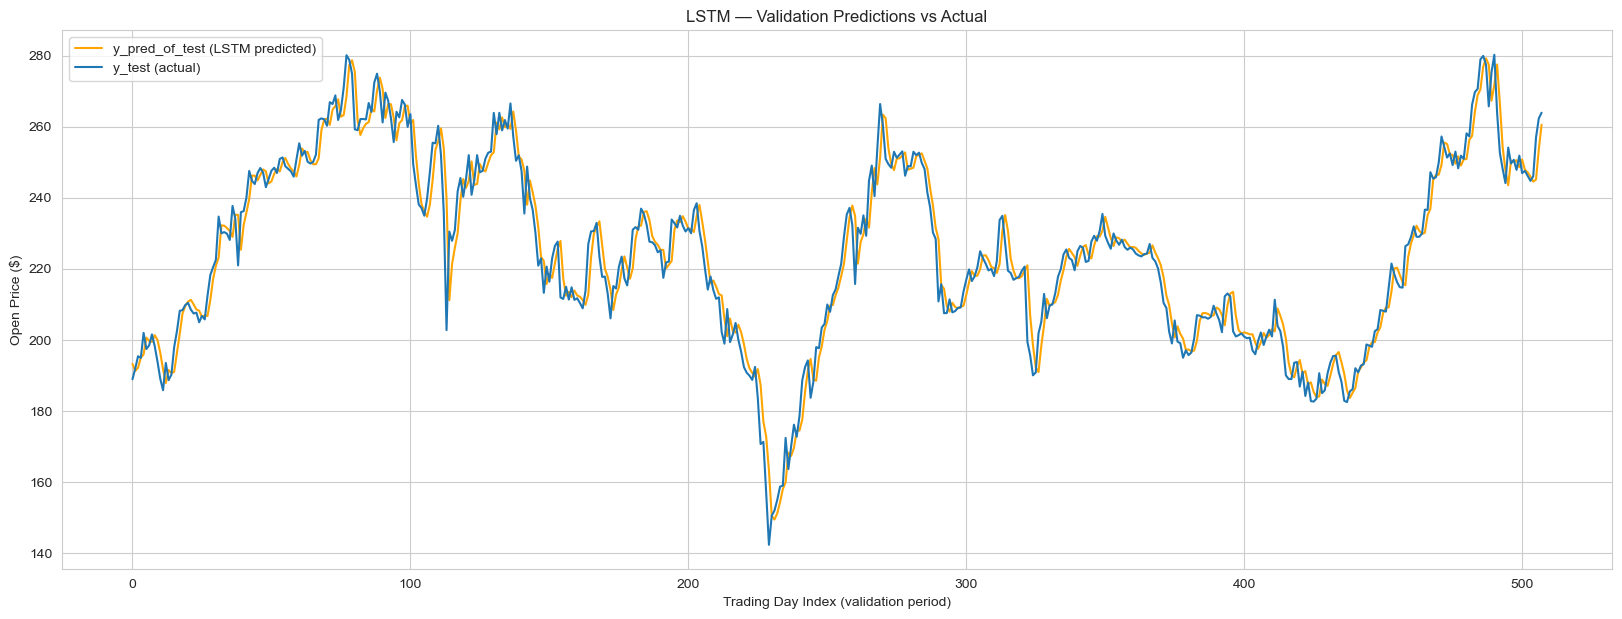

In [55]:
plt.subplots(figsize = (20,7))
plt.plot(y_pred_of_test_lstm, label='y_pred_of_test (LSTM predicted)', c='orange')
plt.plot(y_test, label='y_test (actual)'),
plt.xlabel("Trading Day Index (validation period)")                                    # x-axis label
plt.ylabel("Open Price ($)")                                                            # y-axis label
plt.title("LSTM — Validation Predictions vs Actual")                                    # chart title
plt.legend()                                                                             # show legend
plt.show()                                                                               # render the plot

## Portfolio-ready evaluation and exports

This final section calculates held-out metrics and exports the prediction visuals used in the README.

In [ ]:
import os
os.makedirs("images", exist_ok=True)

actual = np.asarray(y_test).reshape(-1)
rnn_pred = np.asarray(y_pred_of_test).reshape(-1)
lstm_pred = np.asarray(y_pred_of_test_lstm).reshape(-1)
naive_pred = np.r_[train_data["Open"].iloc[-1], actual[:-1]]

def regression_metrics(name, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    direction_actual = np.sign(np.diff(actual))
    direction_predicted = np.sign(np.diff(predicted))
    directional_accuracy = np.mean(direction_actual == direction_predicted) * 100
    print(f"{name}: MAE=${mae:.2f} | RMSE=${rmse:.2f} | R2={r2:.4f} | Directional Accuracy={directional_accuracy:.2f}%")
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "Directional Accuracy": directional_accuracy}

metrics = {
    "Naive baseline": regression_metrics("Naive baseline", naive_pred),
    "SimpleRNN": regression_metrics("SimpleRNN", rnn_pred),
    "LSTM": regression_metrics("LSTM", lstm_pred),
}

dates = pd.to_datetime(validation_data["Date"])

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(dates, actual, label="Actual Open", color="black", linewidth=1.8)
ax.plot(dates, rnn_pred, label="SimpleRNN Prediction", color="#F97316", linewidth=1.4, alpha=0.9)
ax.plot(dates, lstm_pred, label="LSTM Prediction", color="#2563EB", linewidth=1.4, alpha=0.9)
ax.set_title("Tesla Open Price Forecast: RNN vs LSTM", fontsize=16, weight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Open Price (USD)")
ax.legend(frameon=True)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("images/rnn_lstm_validation_predictions.png", dpi=180, bbox_inches="tight")
plt.show()

for model_name, predicted, color, filename in [
    ("SimpleRNN", rnn_pred, "#F97316", "rnn_validation_prediction.png"),
    ("LSTM", lstm_pred, "#2563EB", "lstm_validation_prediction.png"),
]:
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.plot(dates, actual, label="Actual Open", color="black", linewidth=1.8)
    ax.plot(dates, predicted, label=f"{model_name} Prediction", color=color, linewidth=1.5)
    ax.set_title(f"{model_name} Validation Forecast", fontsize=16, weight="bold")
    ax.set_xlabel("Date")
    ax.set_ylabel("Open Price (USD)")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(f"images/{filename}", dpi=180, bbox_inches="tight")
    plt.close(fig)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(pd.to_datetime(data["Date"]), data["Open"], color="#2563EB", linewidth=1.2)
ax.set_title("Tesla Historical Open Price", fontsize=16, weight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Open Price (USD)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("images/tesla_open_history.png", dpi=180, bbox_inches="tight")
plt.close(fig)
